In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
!pip -q install scikit-learn pandas matplotlib seaborn tqdm

In [4]:
import os
import random
import shutil
import copy
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cuda


In [11]:

import os

DRIVE_ROOT = "/content/drive"

def find_unique_file(filename):
    matches = []

    for root, dirs, files in os.walk(DRIVE_ROOT):
        if filename in files:
            matches.append(os.path.join(root, filename))

    if not matches:
        raise FileNotFoundError(f"Cannot find {filename}")

    if len(matches) > 1:
        print(f"Multiple copies of {filename} found:")
        print(*matches, sep="\n")

    return matches[0]

metadata_path = find_unique_file("HAM10000_metadata.csv")
train_csv = find_unique_file("train_split.csv")
val_csv = find_unique_file("val_split.csv")

print("Metadata:", metadata_path)
print("Train CSV:", train_csv)
print("Validation CSV:", val_csv)

import pandas as pd

metadata = pd.read_csv(metadata_path)
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

print("\nMetadata shape:", metadata.shape)
print("Train split shape:", train_df.shape)
print("Validation split shape:", val_df.shape)

print("\nMetadata columns:", metadata.columns.tolist())
print("Train columns:", train_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())


Metadata: /content/drive/.shortcut-targets-by-id/1NfUQEoPUsI6tw0hMvk1aMbuYAeHvgIrc/HAM10000/HAM10000_metadata.csv
Train CSV: /content/drive/.shortcut-targets-by-id/1NfUQEoPUsI6tw0hMvk1aMbuYAeHvgIrc/HAM10000/train_split.csv
Validation CSV: /content/drive/.shortcut-targets-by-id/1NfUQEoPUsI6tw0hMvk1aMbuYAeHvgIrc/HAM10000/val_split.csv

Metadata shape: (10015, 7)
Train split shape: (7991, 7)
Validation split shape: (1008, 7)

Metadata columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Train columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Validation columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [13]:

from pathlib import Path

DRIVE_ROOT = Path("/content/drive")

part1_matches = list(DRIVE_ROOT.rglob("HAM10000_images_part_1"))
part2_matches = list(DRIVE_ROOT.rglob("HAM10000_images_part_2"))

print("Part 1 matches:", part1_matches)
print("Part 2 matches:", part2_matches)


Part 1 matches: [PosixPath('/content/drive/.shortcut-targets-by-id/1NfUQEoPUsI6tw0hMvk1aMbuYAeHvgIrc/HAM10000/HAM10000_images_part_1')]
Part 2 matches: [PosixPath('/content/drive/.shortcut-targets-by-id/1NfUQEoPUsI6tw0hMvk1aMbuYAeHvgIrc/HAM10000/HAM10000_images_part_2')]


In [16]:

from pathlib import Path

# Build image ID -> image file path mapping
image_extensions = {".jpg", ".jpeg", ".png"}
image_paths = {}

for folder in part1_matches + part2_matches:
    for f in folder.iterdir():
        if f.is_file() and f.suffix.lower() in image_extensions:
            image_paths[f.stem] = str(f)

print("Total indexed images:", len(image_paths))

# Attach paths to each DataFrame
for df in [metadata, train_df, val_df]:
    df["image_path"] = df["image_id"].astype(str).map(image_paths)

# Verify
for name, df in [
    ("Metadata", metadata),
    ("Training", train_df),
    ("Validation", val_df)
]:
    print(f"\n{name}: {len(df)} rows")
    print("Missing image paths:", df["image_path"].isna().sum())
    print(df[["image_id", "image_path"]].head(3))


Total indexed images: 10015

Metadata: 10015 rows
Missing image paths: 0
       image_id                                         image_path
0  ISIC_0027419  /content/drive/.shortcut-targets-by-id/1NfUQEo...
1  ISIC_0025030  /content/drive/.shortcut-targets-by-id/1NfUQEo...
2  ISIC_0026769  /content/drive/.shortcut-targets-by-id/1NfUQEo...

Training: 7991 rows
Missing image paths: 0
       image_id                                         image_path
0  ISIC_0027419  /content/drive/.shortcut-targets-by-id/1NfUQEo...
1  ISIC_0025030  /content/drive/.shortcut-targets-by-id/1NfUQEo...
2  ISIC_0026769  /content/drive/.shortcut-targets-by-id/1NfUQEo...

Validation: 1008 rows
Missing image paths: 0
       image_id                                         image_path
0  ISIC_0031326  /content/drive/.shortcut-targets-by-id/1NfUQEo...
1  ISIC_0024324  /content/drive/.shortcut-targets-by-id/1NfUQEo...
2  ISIC_0029559  /content/drive/.shortcut-targets-by-id/1NfUQEo...


In [17]:

# 1. Check for overlapping images
train_ids = set(train_df["image_id"].astype(str))
val_ids = set(val_df["image_id"].astype(str))

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Overlapping image IDs:", len(train_ids & val_ids))

# 2. Check lesion class distribution
print("\nTraining class distribution:")
print(train_df["dx"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["dx"].value_counts().sort_index())

# 3. Check metadata coverage
split_ids = train_ids | val_ids
metadata_ids = set(metadata["image_id"].astype(str))

print("\nImages in neither split:", len(metadata_ids - split_ids))
print("Split IDs absent from metadata:", len(split_ids - metadata_ids))


Training images: 7991
Validation images: 1008
Overlapping image IDs: 0

Training class distribution:
dx
akiec     260
bcc       424
bkl       856
df         97
mel       877
nv       5369
vasc      108
Name: count, dtype: int64

Validation class distribution:
dx
akiec     26
bcc       36
bkl      133
df         8
mel      124
nv       663
vasc      18
Name: count, dtype: int64

Images in neither split: 1016
Split IDs absent from metadata: 0


In [18]:

# Identify records not assigned to train or validation
split_ids = (
    set(train_df["image_id"].astype(str))
    | set(val_df["image_id"].astype(str))
)

remaining = metadata[
    ~metadata["image_id"].astype(str).isin(split_ids)
].copy()

print("Unassigned records:", len(remaining))
print("\nUnassigned class distribution:")
print(remaining["dx"].value_counts().sort_index())

# Check whether the same lesion appears in both splits
train_lesions = set(train_df["lesion_id"].astype(str))
val_lesions = set(val_df["lesion_id"].astype(str))

shared_lesions = train_lesions & val_lesions

print("\nShared lesion IDs:", len(shared_lesions))
print("Train unique lesions:", len(train_lesions))
print("Validation unique lesions:", len(val_lesions))


Unassigned records: 1016

Unassigned class distribution:
dx
akiec     41
bcc       54
bkl      110
df        10
mel      112
nv       673
vasc      16
Name: count, dtype: int64

Shared lesion IDs: 0
Train unique lesions: 5976
Validation unique lesions: 747


In [19]:

# Inspect the unassigned records
print("Unassigned image IDs:")
print(remaining["image_id"].head(10).tolist())

print("\nUnassigned lesion count:",
      remaining["lesion_id"].nunique())

print("\nUnassigned lesions overlapping training:",
      len(set(remaining["lesion_id"]) &
          set(train_df["lesion_id"])))

print("Unassigned lesions overlapping validation:",
      len(set(remaining["lesion_id"]) &
          set(val_df["lesion_id"])))

print("\nMetadata columns:")
print(metadata.columns.tolist())


Unassigned image IDs:
['ISIC_0029176', 'ISIC_0029068', 'ISIC_0029836', 'ISIC_0032129', 'ISIC_0027815', 'ISIC_0030661', 'ISIC_0027053', 'ISIC_0028560', 'ISIC_0031650', 'ISIC_0025016']

Unassigned lesion count: 747

Unassigned lesions overlapping training: 0
Unassigned lesions overlapping validation: 0

Metadata columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'image_path']


In [20]:

# Create the candidate test set from unassigned metadata
test_df = remaining.copy()

# Verify image-level separation
train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])
test_ids = set(test_df["image_id"])

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nImage ID overlaps:")
print("Train vs validation:", len(train_ids & val_ids))
print("Train vs test:", len(train_ids & test_ids))
print("Validation vs test:", len(val_ids & test_ids))

# Verify lesion-level separation
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print("\nLesion ID overlaps:")
print("Train vs validation:", len(train_lesions & val_lesions))
print("Train vs test:", len(train_lesions & test_lesions))
print("Validation vs test:", len(val_lesions & test_lesions))

# Check test image paths
print("\nMissing test image paths:", test_df["image_path"].isna().sum())


Train images: 7991
Validation images: 1008
Test images: 1016

Image ID overlaps:
Train vs validation: 0
Train vs test: 0
Validation vs test: 0

Lesion ID overlaps:
Train vs validation: 0
Train vs test: 0
Validation vs test: 0

Missing test image paths: 0


In [21]:

from PIL import Image
import numpy as np

# Verify one image from each split
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    row = df.iloc[0]
    path = row["image_path"]

    with Image.open(path) as img:
        print(
            f"{name}:",
            "image_id =", row["image_id"],
            "| label =", row["dx"],
            "| size =", img.size,
            "| mode =", img.mode
        )
        img.verify()

# Confirm all seven classes
classes = sorted(metadata["dx"].unique().tolist())
print("\nClasses:", classes)
print("Number of classes:", len(classes))


Train: image_id = ISIC_0027419 | label = bkl | size = (600, 450) | mode = RGB
Validation: image_id = ISIC_0031326 | label = bkl | size = (600, 450) | mode = RGB
Test: image_id = ISIC_0029176 | label = bkl | size = (600, 450) | mode = RGB

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


In [22]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15

tf.keras.utils.set_random_seed(SEED)

classes = sorted(metadata["dx"].unique().tolist())
class_to_idx = {label: i for i, label in enumerate(classes)}

for df in [train_df, val_df, test_df]:
    df["label"] = df["dx"].map(class_to_idx).astype("int32")

print("Classes:", class_to_idx)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [23]:

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(df, training=False):
    paths = df["image_path"].astype(str).to_numpy()
    labels = df["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(df), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Image pipelines created.")


Image pipelines created.


In [24]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,663 (432.28 KB)

 Trainable params: 110,663 (432.28 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=train_df["label"].to_numpy()
)

class_weights = dict(enumerate(weights))
print("Class weights:", class_weights)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/baseline_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)


Class weights: {0: np.float64(4.390659340659341), 1: np.float64(2.6923854447439353), 2: np.float64(1.333611481975968), 3: np.float64(11.76877761413844), 4: np.float64(1.3016777976869196), 5: np.float64(0.21262272836122714), 6: np.float64(10.57010582010582)}
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 47s 187ms/step - accuracy: 0.4593 - loss: 1.7114 - val_accuracy: 0.5089 - val_loss: 1.3339 - learning_rate: 2.5000e-04
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 82s 187ms/step - accuracy: 0.4672 - loss: 1.6854 - val_accuracy: 0.4375 - val_loss: 1.5240 - learning_rate: 2.5000e-04
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 184ms/step - accuracy: 0.4464 - loss: 1.6656 - val_accuracy: 0.4712 - val_loss: 1.3843 - learning_rate: 2.5000e-04
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 46s 183ms/step - accuracy: 0.4486 - loss: 1.6257 - val_accuracy: 0.4891 - val_loss: 1.3429 - learning_rate: 1.2500e-04
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 45s 180ms/step - accuracy: 0.4349 - loss: 1.6076 - val_accuracy: 0

In [30]:

import numpy as np
from sklearn.metrics import f1_score
import tensorflow as tf

class ValidationF1Callback(tf.keras.callbacks.Callback):
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        y_true = np.concatenate([
            labels.numpy() for _, labels in self.val_ds
        ])

        y_prob = self.model.predict(self.val_ds, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)

        macro_f1 = f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        )

        print(
            f"\nValidation Macro F1: {macro_f1:.4f}"
            f" | Weighted F1: {weighted_f1:.4f}"
        )


In [31]:

model = tf.keras.models.load_model("/content/baseline_cnn.keras")

history_resume = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        ValidationF1Callback(val_ds),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        ),

        tf.keras.callbacks.ModelCheckpoint(
            "/content/baseline_cnn.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]
)


Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.4492 - loss: 1.6713
Validation Macro F1: 0.2439 | Weighted F1: 0.5233
250/250 ━━━━━━━━━━━━━━━━━━━━ 63s 236ms/step - accuracy: 0.4574 - loss: 1.6832 - val_accuracy: 0.4633 - val_loss: 1.5403 - learning_rate: 2.5000e-04
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.4551 - loss: 1.6028
Validation Macro F1: 0.2420 | Weighted F1: 0.5309
250/250 ━━━━━━━━━━━━━━━━━━━━ 57s 228ms/step - accuracy: 0.4551 - loss: 1.6483 - val_accuracy: 0.4712 - val_loss: 1.4367 - learning_rate: 2.5000e-04
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.4435 - loss: 1.5831
Validation Macro F1: 0.2828 | Weighted F1: 0.5547
250/250 ━━━━━━━━━━━━━━━━━━━━ 57s 228ms/step - accuracy: 0.4377 - loss: 1.6223 - val_accuracy: 0.5010 - val_loss: 1.3590 - learning_rate: 2.5000e-04
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.4403 - loss: 1.6055
Validation Macro F1: 0.2760 | Weighted F1: 0.5465
250/

32/32 ━━━━━━━━━━━━━━━━━━━━ 345s 11s/step
Test Accuracy: 0.501
Test Macro F1: 0.3321
Test Weighted F1: 0.5485

Classification Report:
              precision    recall  f1-score   support

       akiec     0.2105    0.2927    0.2449        41
         bcc     0.2793    0.5741    0.3758        54
         bkl     0.3396    0.1636    0.2209       110
          df     0.0588    0.4000    0.1026        10
         mel     0.2550    0.6875    0.3720       112
          nv     0.9251    0.5319    0.6755       673
        vasc     0.2368    0.5625    0.3333        16

    accuracy                         0.5010      1016
   macro avg     0.3293    0.4589    0.3321      1016
weighted avg     0.7053    0.5010    0.5485      1016



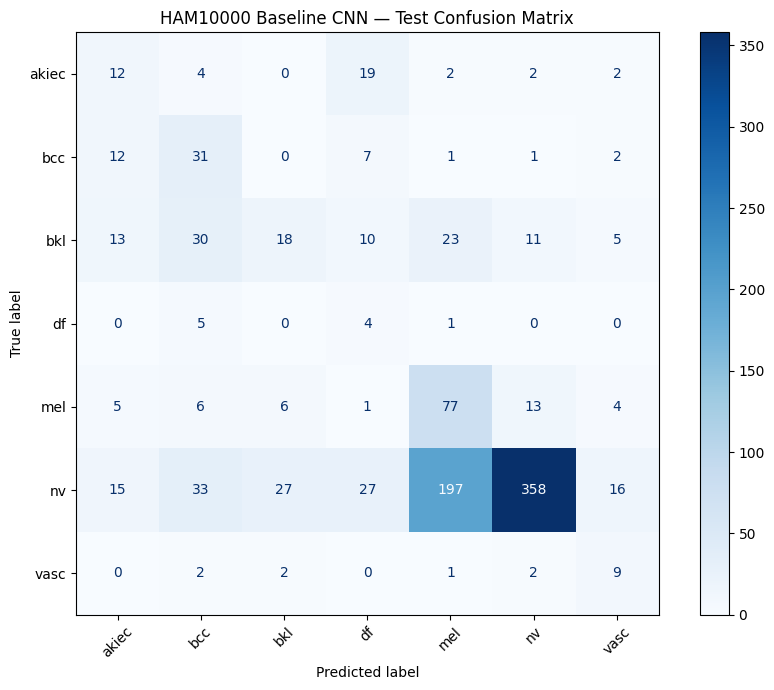

In [32]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best saved checkpoint
model = tf.keras.models.load_model("/content/baseline_cnn.keras")

# Predict on the untouched test set
y_true = test_df["label"].to_numpy()
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Overall metrics
print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Test Weighted F1:", round(
    f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
))

# Per-class precision, recall and F1
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("HAM10000 Baseline CNN — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [33]:

import os
import shutil
import pandas as pd
import json

from google.colab import drive
drive.mount('/content/drive')

# Create a permanent project folder
SAVE_DIR = "/content/drive/MyDrive/HAM10000_Project"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(f"{SAVE_DIR}/models", exist_ok=True)
os.makedirs(f"{SAVE_DIR}/results", exist_ok=True)

# Save available model checkpoints
model_files = {
    "/content/baseline_cnn.keras":
        f"{SAVE_DIR}/models/baseline_cnn.keras",
    "/content/resnet50_best.keras":
        f"{SAVE_DIR}/models/resnet50_best.keras"
}

for src, dst in model_files.items():
    if os.path.exists(src):
        shutil.copy2(src, dst)
        print("Saved:", dst)
    else:
        print("Not found yet:", src)

# Save training histories
histories = {
    "baseline_resumed": globals().get("history_resume"),
    "resnet50": globals().get("resnet_history")
}

for name, hist in histories.items():
    if hist is not None:
        pd.DataFrame(hist.history).to_csv(
            f"{SAVE_DIR}/results/{name}_history.csv",
            index=False
        )
        print("Saved history:", name)

print("\nProject files saved in:", SAVE_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: /content/drive/MyDrive/HAM10000_Project/models/baseline_cnn.keras
Not found yet: /content/resnet50_best.keras
Saved history: baseline_resumed

Project files saved in: /content/drive/MyDrive/HAM10000_Project
